In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

simulator = AerSimulator()

print("Libraries imported successfully!")

Libraries imported successfully!


## Experiment 1: Biased Quantum Coin

**Prediction before execution:** The qubit starts in state |0⟩. An H gate creates a superposition, and an RY rotation changes the measurement probabilities. I predict that outcome `1` will occur more frequently than outcome `0`.

In [3]:
circuit_1 = QuantumCircuit(1, 1)

circuit_1.h(0)
circuit_1.ry(np.pi / 3, 0)
circuit_1.measure(0, 0)

print(circuit_1.draw(output="text"))

     ┌───┐┌─────────┐┌─┐
  q: ┤ H ├┤ Ry(π/3) ├┤M├
     └───┘└─────────┘└╥┘
c: 1/═════════════════╩═
                      0 


In [4]:
compiled_1 = transpile(circuit_1, simulator)

result_1 = simulator.run(
    compiled_1,
    shots=100
).result()

counts_1 = result_1.get_counts()

print("Measurement results:", counts_1)
print("Total shots:", sum(counts_1.values()))

Measurement results: {'1': 92, '0': 8}
Total shots: 100


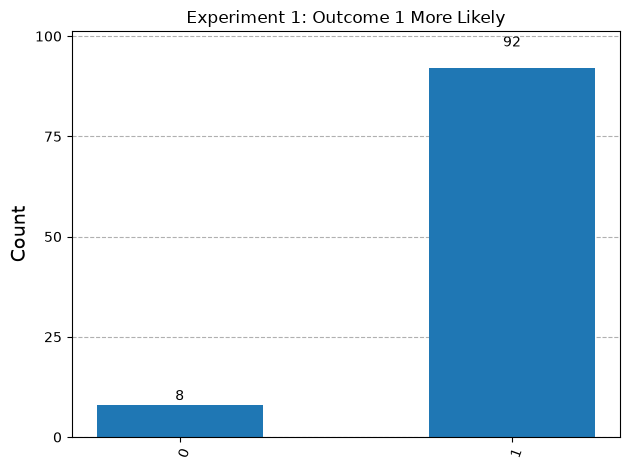

In [5]:
fig = plot_histogram(
    counts_1,
    title="Experiment 1: Outcome 1 More Likely"
)
display(fig)

### Experiment 1: Results and Explanation

**Quantum gates:** H followed by RY(π/3).

**Predicted probabilities:**
- Outcome `0`: approximately 6.7%
- Outcome `1`: approximately 93.3%

**Actual measurement results:**
- Outcome 0: 8 shots (8%)
- Outcome 1: 92 shots (92%)

**Explanation:** The H gate creates a superposition. The RY rotation changes the amplitudes of the basis states, making outcome `1` much more likely than outcome `0`. The circuit was executed for 100 shots, and the histogram displays the observed distribution.

## Experiment 2: Make Outcome 0 More Likely

**Prediction before execution:** The qubit starts in state |0⟩. An H gate creates a superposition, and an RY rotation by -π/3 changes the amplitudes so that outcome `0` is more likely than outcome `1`.

In [6]:
circuit_2 = QuantumCircuit(1, 1)
circuit_2.h(0)
circuit_2.ry(-np.pi / 3, 0)
circuit_2.measure(0, 0)
print(circuit_2.draw(output="text"))

     ┌───┐┌──────────┐┌─┐
  q: ┤ H ├┤ Ry(-π/3) ├┤M├
     └───┘└──────────┘└╥┘
c: 1/══════════════════╩═
                       0 


In [7]:
compiled_2 = transpile(circuit_2, simulator)

result_2 = simulator.run(
    compiled_2,
    shots=100
).result()

counts_2 = result_2.get_counts()

print("Measurement results:", counts_2)
print("Total shots:", sum(counts_2.values()))

Measurement results: {'0': 94, '1': 6}
Total shots: 100


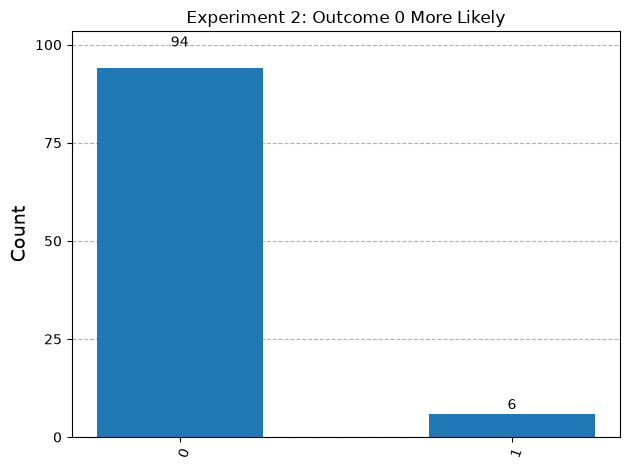

In [9]:
fig = plot_histogram(
    counts_2,
    title="Experiment 2: Outcome 0 More Likely"
)
display(fig)

## Comparison of Biased Quantum Coins

| Feature             | Experiment 1   | Experiment 2   |
|---------------------|----------------|----------------|
| Rotation gate       | RY(π/3)        | RY(-π/3)       |
| More likely outcome | `1`            | `0`            |
| Number of shots     | 100            | 100            |
| Results             | {'1':92,'0':8} |{'0': 94,'1': 6}|

### Analysis

Changing the sign of the rotation angle changes the measurement probabilities. Experiment 1 favours outcome `1`, whereas Experiment 2 favours outcome `0`. The histograms illustrate how different gate operations can create different measurement distributions.

## Experiment 3: A Different Degree of Bias

**Prediction before execution:** This circuit uses a smaller rotation angle, RY(π/6), after the H gate. It should produce a less extreme bias than Experiment 1.

In [10]:
circuit_3 = QuantumCircuit(1, 1)
circuit_3.h(0)
circuit_3.ry(np.pi / 6, 0)
circuit_3.measure(0, 0)

print(circuit_3.draw(output="text"))

     ┌───┐┌─────────┐┌─┐
  q: ┤ H ├┤ Ry(π/6) ├┤M├
     └───┘└─────────┘└╥┘
c: 1/═════════════════╩═
                      0 


In [11]:
compiled_3 = transpile(circuit_3, simulator)

result_3 = simulator.run(
    compiled_3,
    shots=100
).result()

counts_3 = result_3.get_counts()

print("Measurement results:", counts_3)
print("Total shots:", sum(counts_3.values()))

Measurement results: {'1': 70, '0': 30}
Total shots: 100


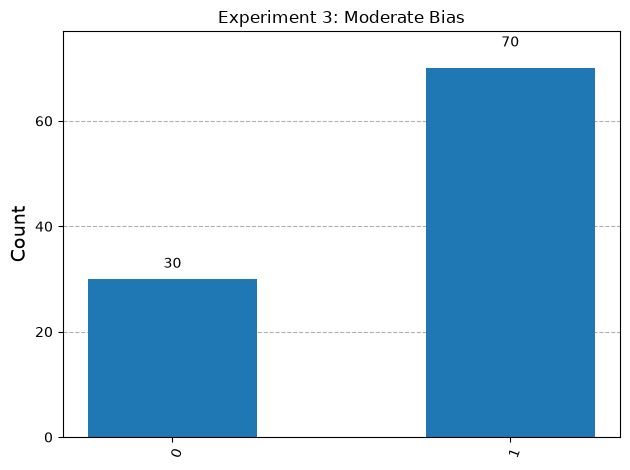

In [12]:
fig = plot_histogram(
    counts_3,
    title="Experiment 3: Moderate Bias"
)
display(fig)

## Conclusion

This challenge demonstrated that quantum gates can control measurement probabilities. By applying an H gate followed by different RY rotations, we created circuits favouring either `0` or `1`. Changing the rotation angle changed the degree of bias. The measurement results from 100 shots and the histograms helped compare the observed distributions with the theoretical predictions.

## Challenge Question

**How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?**

Quantum gates change the state of a qubit by modifying the amplitudes and phases of its basis states. The squared magnitudes of the amplitudes determine the measurement probabilities. By applying suitable gates and choosing different rotation angles, we can make one measurement outcome more likely than the other.